In [1]:
from pathlib import Path

from src.load_spectra import BOSZSpectra
from src.load_telluric import TelluricSpectra
from src.model import ContinuumNormalizer

import numpy as np
from matplotlib import pyplot as plt

Importing packages
End importing


In [2]:
bosz_root = Path("/home/mward19/nobackup/autodelete/bosz-spectra")
telluric_root = Path("/home/mward19/nobackup/autodelete/telluric")

In [3]:
# Same parameters as the caches the NMFs were built from, so nothing is recomputed
bosz = BOSZSpectra(
    bosz_root / Path("data"),
    300_000,
    115_000,
    D=3000,
    wave_min=3000,
    wave_max=7000,
    cache_dir=bosz_root / Path("processed-harps"),
    # debug_max_F_spectra=10000,
    spectra_per_file=1000,
)
telluric = TelluricSpectra(
    telluric_root / Path("TellPCA_3000_10500_R120000.fits"),
    D=3000,
    wave_min=3000,
    wave_max=7000,
    R_out=115_000,
    n_pca=4,
    t_floor=1e-10,
    cache_dir=telluric_root / Path("processed"),
)

Parsing root directory: 100%|██████████| 628620/628620 [00:07<00:00, 79554.09file/s]


In [4]:
wave = bosz.wave_out
# Use the short full-NMF run already cached for the MARCS-only, Teff <= 8000 K selection.
cn = ContinuumNormalizer(
    bosz,
    telluric,
    flux_errors=1e-8 * np.ones(3000),
    order_wavelengths=wave,
    F_kwargs=dict(max_iter=100, tol=1e-4),
    F_filter=dict(atmos=("mp", "ms"), teff_max=8000),
    force_recompute_F=True,
)

Training on 396108 of 628620 selected spectra ({'atmos': ['mp', 'ms'], 'teff_max': 8000.0})
Skipping cached nmf_F_full; force_recompute_F=True
Preparing sparse BOSZ matrix


Loading cached sparse matrix: 100%|█████████▉| 8.50G/8.50G [05:25<00:00, 28.1MB/s]


Sparse BOSZ matrix ready: shape=(628620, 3000), nnz=1,140,949,704, elapsed=325.2s
Selecting 396,108 training rows from sparse matrix
[NMF] Gathering 396,108 training rows into the fit matrix...
[NMF] Fit matrix ready: shape=(396108, 3000), nnz=938,948,151 (242.5s)
Training matrix ready: shape=(396108, 3000), nnz=938,948,151, density=79.01%, selection_elapsed=242.5s
Starting NMF initialization and coordinate descent (max_iter=100, init=nndsvda)
[NMF] Entering sklearn NMF.fit (initialization may take a while)...
violation: 1.0
violation: 0.016575100718858062
violation: 0.02207855963083606
violation: 0.021631707847965493
violation: 0.015375701658160693
violation: 0.01061145250861862
violation: 0.008524943587726683
violation: 0.0075247262972404005
violation: 0.006071084724918958
violation: 0.005093170522813986
violation: 0.005072501841820605
violation: 0.004881905928838508
violation: 0.004310572753443949
violation: 0.004267434373436921
violation: 0.0037760522541928493
violation: 0.00359167

KeyboardInterrupt: 

In [ ]:
F = np.load("/home/mward19/nobackup/autodelete/bosz-spectra/processed-harps/nmf_F_last_epoch_f7092c703d.npy")

In [ ]:
F.shape

(16, 3000)

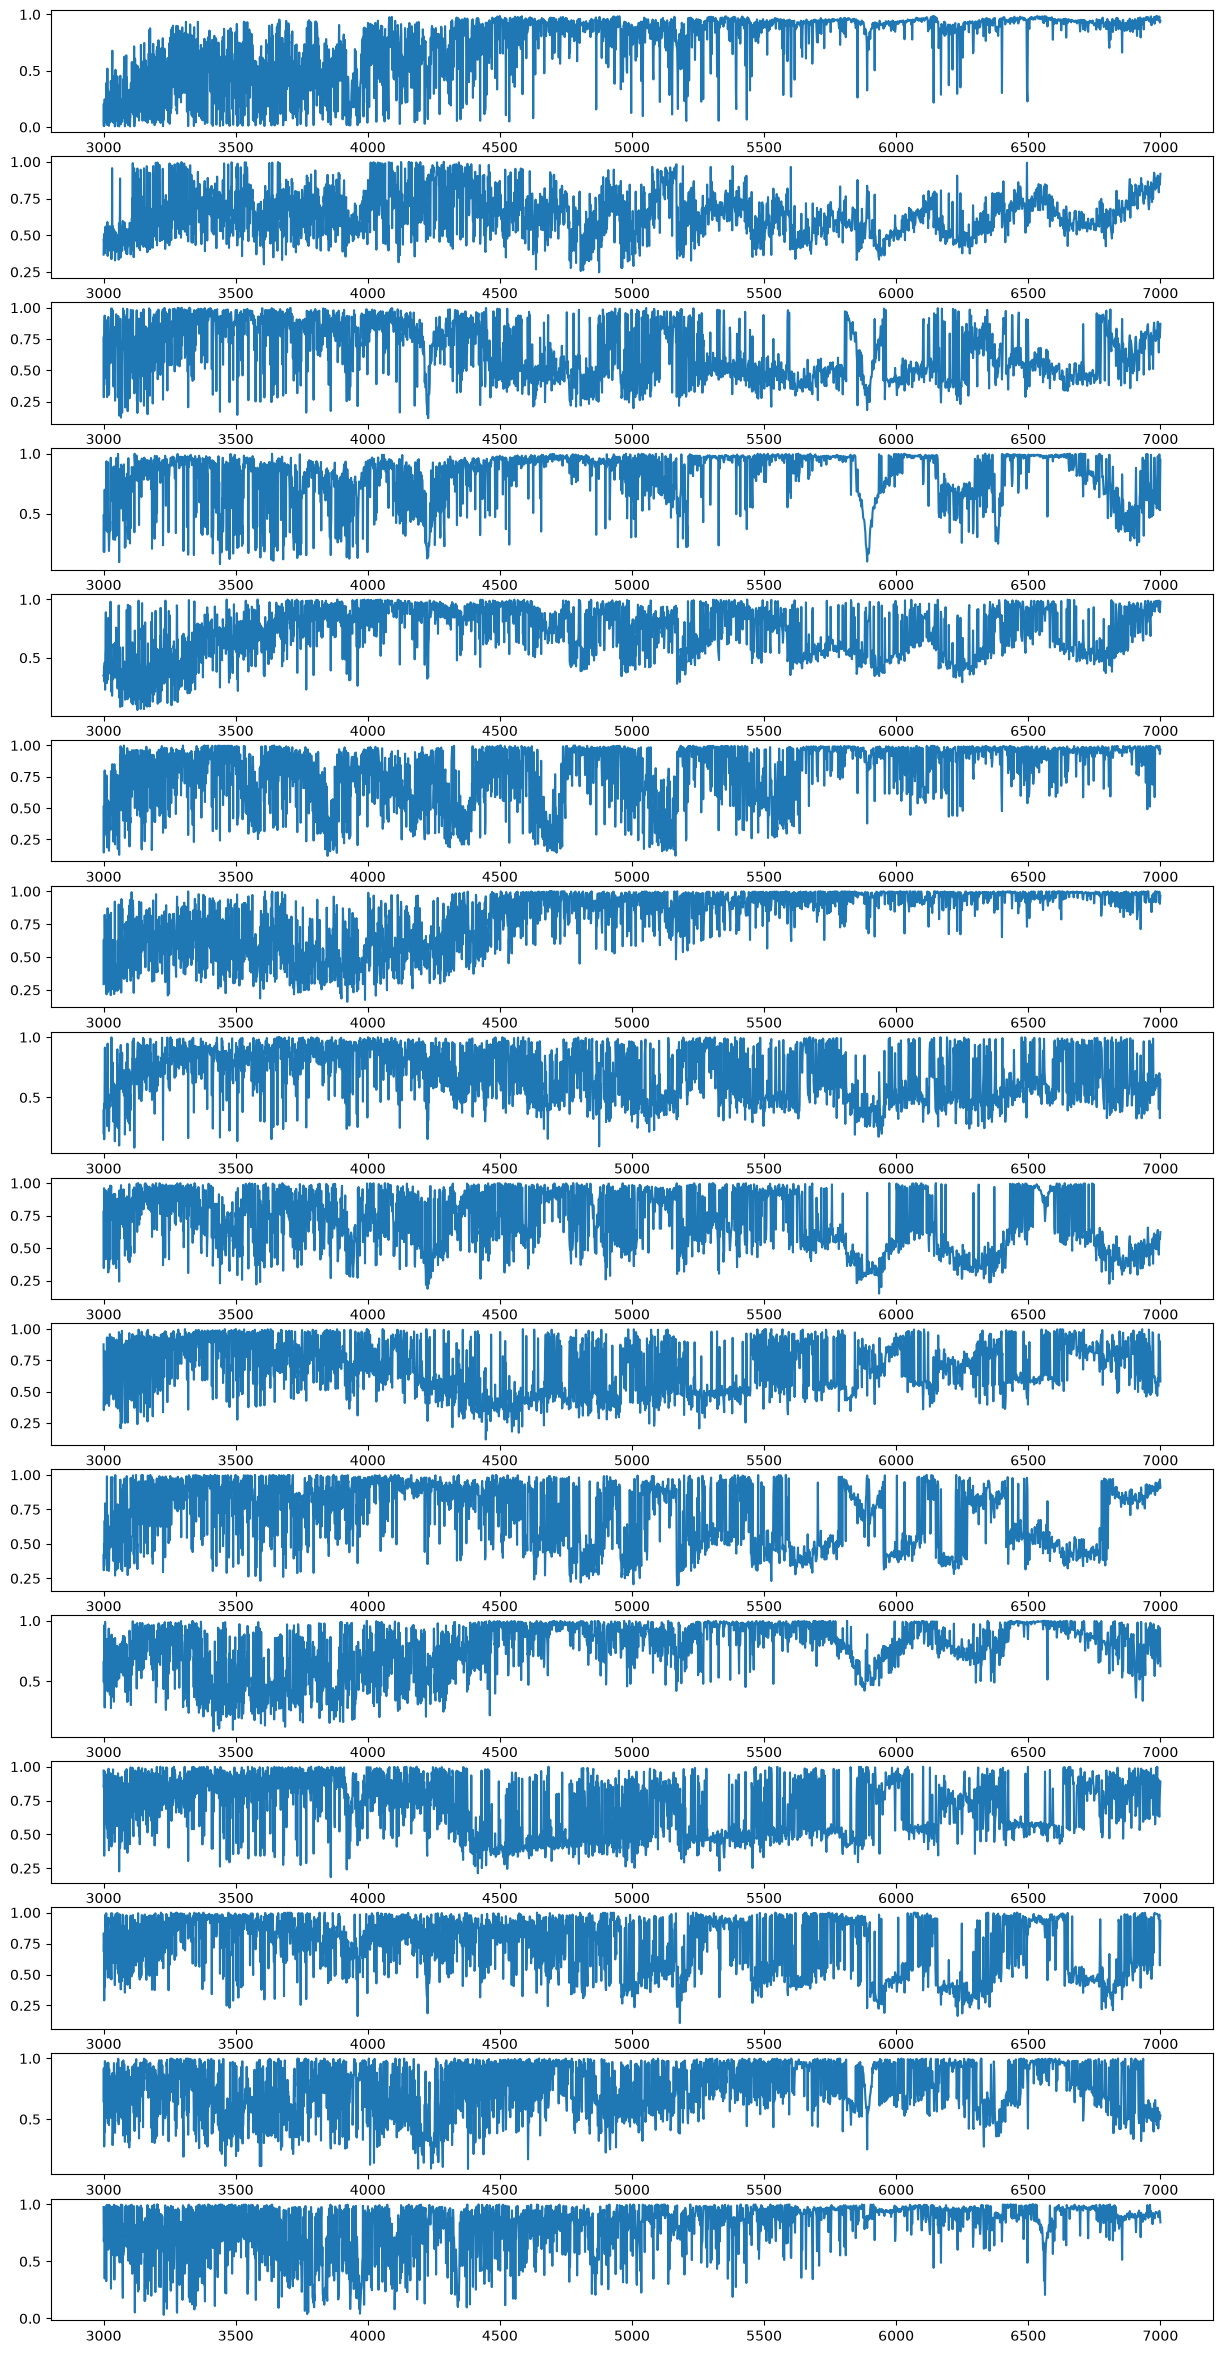

In [ ]:
_n_vecs = 16
_fig, _axes = plt.subplots(_n_vecs, figsize=(15, 30))

for _i, _ax in enumerate(_axes):
    _ax.plot(wave, np.exp(-F[_i]))

plt.show()

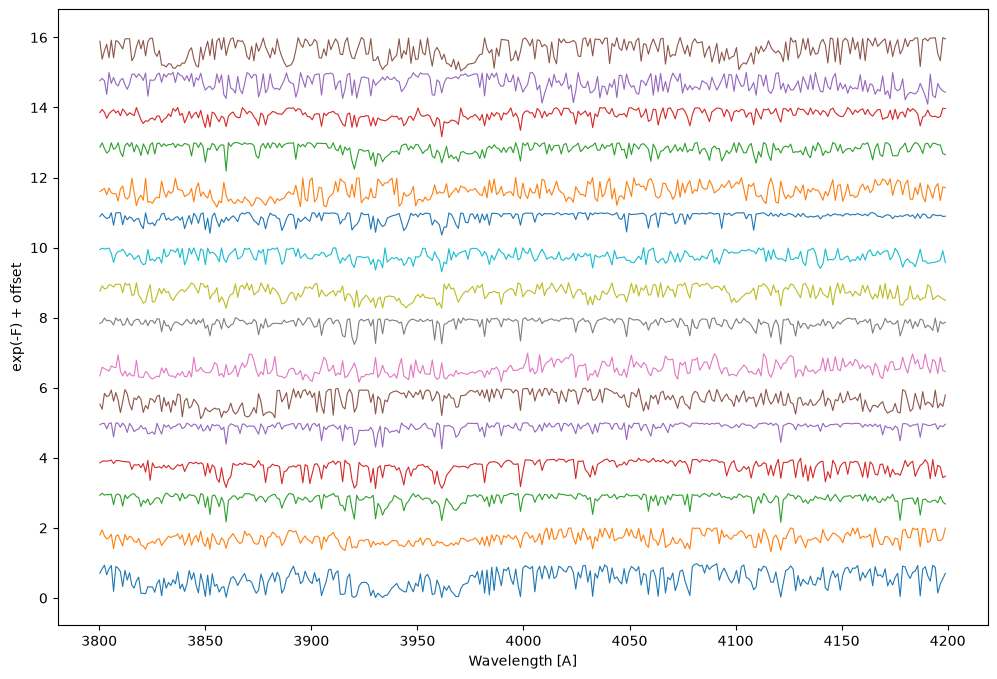

In [ ]:
# Like Figure 1 of Casey et al. (2026): basis vectors exp(-F) with offsets, 3800-4200 A
_window = (wave >= 3800) & (wave <= 4200)
_fig, _ax = plt.subplots(figsize=(12, 8))
for _i, _f in enumerate(F):
    _ax.plot(wave[_window], np.exp(-_f[_window]) + _i, lw=0.8)
_ax.set_xlabel("Wavelength [A]")
_ax.set_ylabel("exp(-F) + offset")
plt.show()